In [ ]:
!python -m spacy download pt_core_news_lg

In [60]:
import pymupdf
import pandas as pd 
import glob
import os 
from collections import Counter
import spacy
import re
import plotly.express as px
import plotly.graph_objects as go

from plotly.subplots import make_subplots


#### Carregando dados

In [34]:
BASE_PATH = "/home/gustavoreis/Projetos/Homelab/ACartomanteRAG"

df_coletanea_pdfs = pd.read_csv(
    "/home/gustavoreis/Projetos/Homelab/ACartomanteRAG/"
    "Dataset/metadata/obras_machado_assis_deduplicadas.csv"
)

df_coletanea_pdfs

,titulo,autor,fonte,formato,tamanho,acessos,url_detalhe,url_download,downloads_encontrados,pdf_path
0,A Carteira,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,.pdf,"30,24 KB",114102,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,Dataset/raw/A_Carteira.pdf
1,A Cartomante,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,.pdf,"39,64 KB",154851,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,Dataset/raw/A_Cartomante.pdf
2,A Causa Secreta,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,.pdf,"40,80 KB",53202,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,Dataset/raw/A_Causa_Secreta.pdf
3,A chave,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"138,02 KB",55648,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,Dataset/raw/A_chave.pdf
4,A Chinela Turca,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,.pdf,"85,09 KB",63578,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,Dataset/raw/A_Chinela_Turca.pdf
...,...,...,...,...,...,...,...,...,...,...
253,Viver!,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,.pdf,"73,30 KB",11632,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,Dataset/raw/Viver!.pdf
254,Várias Histórias,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,.pdf,"455,17 KB",24726,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,Dataset/raw/Várias_Histórias.pdf
255,Vênus! divina vênus!,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"93,37 KB",8184,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,Dataset/raw/Vênus!_divina_vênus!.pdf
256,Última receita,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"86,65 KB",5506,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,Dataset/raw/Última_receita.pdf


transforma path em absoluto 

In [35]:
df_coletanea_pdfs["pdf_path"] = df_coletanea_pdfs["pdf_path"].apply(
    lambda x: os.path.join(BASE_PATH, x)
    if pd.notna(x)
    else None
)
df_coletanea_pdfs

,titulo,autor,fonte,formato,tamanho,acessos,url_detalhe,url_download,downloads_encontrados,pdf_path
0,A Carteira,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,.pdf,"30,24 KB",114102,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
1,A Cartomante,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,.pdf,"39,64 KB",154851,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
2,A Causa Secreta,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,.pdf,"40,80 KB",53202,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
3,A chave,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"138,02 KB",55648,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
4,A Chinela Turca,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,.pdf,"85,09 KB",63578,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
...,...,...,...,...,...,...,...,...,...,...
253,Viver!,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,.pdf,"73,30 KB",11632,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
254,Várias Histórias,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,.pdf,"455,17 KB",24726,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
255,Vênus! divina vênus!,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"93,37 KB",8184,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
256,Última receita,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"86,65 KB",5506,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...


In [36]:
paths = df_coletanea_pdfs["pdf_path"].dropna()

existentes = paths.apply(os.path.isfile)

print(f"{existentes.sum()} de {len(paths)} existentes")

if not existentes.all():
    print("\nNão encontrados:")
    for path in paths[~existentes]:
        print(path)

257 de 257 existentes


Um pdf não existia dado que em dropna perdemos 1 amostra de 258 para 257 , validando qual :

In [37]:
df_coletanea_pdfs[df_coletanea_pdfs["pdf_path"].isna()]

,titulo,autor,fonte,formato,tamanho,acessos,url_detalhe,url_download,downloads_encontrados,pdf_path
167,O Rei dos Caiporas,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"0,00 KB",8240,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,None


procurando na fonte o pdf nao esta disponivel no server: 

https://dominiopublico.mec.gov.br/pesquisa/DetalheObraForm.do?select_action=&co_obra=17481

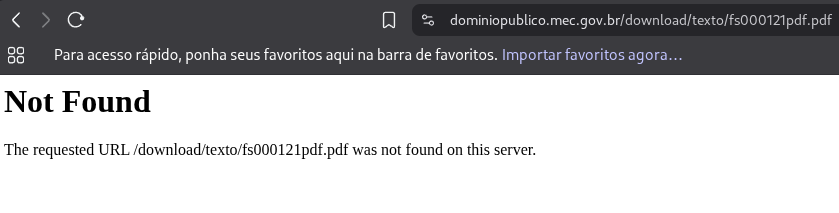

necessario atualizar o crawler de download para lidar quando não houver pdfs. 

Por hora limpar do df


In [38]:
df_coletanea_pdfs.dropna(inplace=True)
df_coletanea_pdfs

,titulo,autor,fonte,formato,tamanho,acessos,url_detalhe,url_download,downloads_encontrados,pdf_path
0,A Carteira,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,.pdf,"30,24 KB",114102,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
1,A Cartomante,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,.pdf,"39,64 KB",154851,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
2,A Causa Secreta,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,.pdf,"40,80 KB",53202,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
3,A chave,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"138,02 KB",55648,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
4,A Chinela Turca,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,.pdf,"85,09 KB",63578,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
...,...,...,...,...,...,...,...,...,...,...
253,Viver!,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,.pdf,"73,30 KB",11632,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
254,Várias Histórias,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,.pdf,"455,17 KB",24726,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
255,Vênus! divina vênus!,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"93,37 KB",8184,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
256,Última receita,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"86,65 KB",5506,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...


#### Analise quantitativa bruta

removendo colunas não necessárias para essa analise

In [39]:
df_coletanea_infos = df_coletanea_pdfs.copy()
df_coletanea_infos.drop(columns=["formato","url_detalhe","url_download","downloads_encontrados"], inplace=True)
df_coletanea_infos

,titulo,autor,fonte,tamanho,acessos,pdf_path
0,A Carteira,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,"30,24 KB",114102,/home/gustavoreis/Projetos/Homelab/ACartomante...
1,A Cartomante,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,"39,64 KB",154851,/home/gustavoreis/Projetos/Homelab/ACartomante...
2,A Causa Secreta,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,"40,80 KB",53202,/home/gustavoreis/Projetos/Homelab/ACartomante...
3,A chave,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,"138,02 KB",55648,/home/gustavoreis/Projetos/Homelab/ACartomante...
4,A Chinela Turca,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,"85,09 KB",63578,/home/gustavoreis/Projetos/Homelab/ACartomante...
...,...,...,...,...,...,...
253,Viver!,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,"73,30 KB",11632,/home/gustavoreis/Projetos/Homelab/ACartomante...
254,Várias Histórias,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,"455,17 KB",24726,/home/gustavoreis/Projetos/Homelab/ACartomante...
255,Vênus! divina vênus!,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,"93,37 KB",8184,/home/gustavoreis/Projetos/Homelab/ACartomante...
256,Última receita,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,"86,65 KB",5506,/home/gustavoreis/Projetos/Homelab/ACartomante...


Extraindo metricas estatisticas do corpus textual 

In [40]:
def extrair_metricas_pdf(pdf_path):
    doc = pymupdf.open(pdf_path)

    qtd_paginas = doc.page_count
    qtd_caracteres = 0
    qtd_palavras = 0
    qtd_paragrafos = 0

    for page in doc:
        texto = page.get_text()
       
        qtd_caracteres += len(texto)

        
        palavras = re.findall(r"\b\w+\b", texto, flags=re.UNICODE)
        qtd_palavras += len(palavras)

        blocos = page.get_text("blocks")
        for bloco in blocos:
            texto_bloco = bloco[4].strip()

            if texto_bloco:
                qtd_paragrafos += 1

    doc.close()

    return pd.Series({
        "count_pages": qtd_paginas,
        "count_chars": qtd_caracteres,
        "count_words": qtd_palavras,
        "count_paragraphs": qtd_paragrafos,
    })

In [41]:
df_coletanea_infos[
    [
        "count_pages",
        "count_chars",
        "count_words",
        "count_paragraphs",
    ]
] = df_coletanea_infos["pdf_path"].apply(
    extrair_metricas_pdf
)

In [42]:
df_coletanea_infos

,titulo,autor,fonte,tamanho,acessos,pdf_path,count_pages,count_chars,count_words,count_paragraphs
0,A Carteira,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,"30,24 KB",114102,/home/gustavoreis/Projetos/Homelab/ACartomante...,4,7835,1375,37
1,A Cartomante,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,"39,64 KB",154851,/home/gustavoreis/Projetos/Homelab/ACartomante...,8,18532,3280,82
2,A Causa Secreta,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,"40,80 KB",53202,/home/gustavoreis/Projetos/Homelab/ACartomante...,8,19875,3497,86
3,A chave,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,"138,02 KB",55648,/home/gustavoreis/Projetos/Homelab/ACartomante...,17,37790,6648,582
4,A Chinela Turca,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,"85,09 KB",63578,/home/gustavoreis/Projetos/Homelab/ACartomante...,10,21437,3669,107
...,...,...,...,...,...,...,...,...,...,...
253,Viver!,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,"73,30 KB",11632,/home/gustavoreis/Projetos/Homelab/ACartomante...,6,15238,2575,11
254,Várias Histórias,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,"455,17 KB",24726,/home/gustavoreis/Projetos/Homelab/ACartomante...,56,270751,47267,81
255,Vênus! divina vênus!,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,"93,37 KB",8184,/home/gustavoreis/Projetos/Homelab/ACartomante...,9,20308,3467,306
256,Última receita,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,"86,65 KB",5506,/home/gustavoreis/Projetos/Homelab/ACartomante...,7,11566,1972,221


In [43]:
print(df_coletanea_infos["count_words"].mean())
print(df_coletanea_infos["count_words"].sum())

9054.2140077821
2326933


Estamos olhando para 257 obras: 
que somam : 
* 2.326.933 palavras escritas ! Haja Tinta!
* Numa media de 9054.21 palavras por obra

vamos olhar quantas palavras compunham o vocabulário de assis? Aqui vai ficar dificil, porque essas obras em dominio publico podem não ser fidedignas aos manuscritos originais e acabarem representando adapatação ao acordo ortografico da lingua portuguesa do ano que foram disponibilidas pela fonte responsavel

In [53]:
def contar_palavras_corpus(df, tamanho_minimo=0):
    contador = Counter()

    for pdf_path in df["pdf_path"].dropna():

        with pymupdf.open(pdf_path) as doc:

            for page in doc:
                texto = page.get_text().lower()

                palavras = re.findall(
                    r"\b\w+\b",
                    texto,
                    flags=re.UNICODE,
                )

                palavras = [
                    palavra
                    for palavra in palavras
                    if len(palavra) > tamanho_minimo
                ]

                contador.update(palavras)

    return contador


contador_palavras = contar_palavras_corpus(
    df_coletanea_infos
)

55,937 palavras unicas !  De acordo com  a wikipedia em https://pt.wikipedia.org/wiki/L%C3%ADngua_portuguesa 

A academia brasileira de letras estima 356mil unidades lexicais (palavra isolada) na lingua portuguesa 

nisso Machado de assis cobriu 15,71% dese corpo lexical , o bravo 

In [54]:
print("Total de palavras:", contador_palavras.total())
print("Mais frequentes:", contador_palavras.most_common(20))

Total de palavras: 2326933
Mais frequentes: [('a', 91720), ('que', 84103), ('de', 77644), ('o', 72204), ('e', 69288), ('não', 42942), ('se', 32763), ('um', 28809), ('do', 28377), ('da', 24716), ('os', 21710), ('é', 21291), ('uma', 19108), ('com', 19054), ('lhe', 18353), ('em', 17783), ('para', 16883), ('as', 16530), ('mas', 16329), ('me', 15271)]


Bom vendo as mais usadas são conectores e artigos, vamos fazer um filtro de palavras maiores que 3 letras, pra termos uma ideia melhor do que ele mais usava 

In [56]:
contador_palavras = contar_palavras_corpus(
    df_coletanea_infos, tamanho_minimo=3
)

print(
    f"Palavras únicas (> 3 letras): "
    f"{len(contador_palavras):,}"
)

Palavras únicas (> 3 letras): 54,735


In [58]:
contador_palavras.most_common(20)

[('para', 16883),
 ('mais', 10939),
 ('como', 9588),
 ('disse', 6347),
 ('quando', 5440),
 ('casa', 4965),
 ('depois', 4634),
 ('tudo', 4493),
 ('tinha', 4454),
 ('ainda', 4353),
 ('tempo', 4266),
 ('nada', 3987),
 ('muito', 3965),
 ('olhos', 3957),
 ('minha', 3716),
 ('mesmo', 3649),
 ('outro', 3602),
 ('outra', 3496),
 ('estava', 3437),
 ('esta', 3357)]

Bom, ainda temos o problema dos conectivos e tempos verbais, mas ja se aproxima da estruta dos substantivos, faremos agora um filtro mais orientado, a manter substantivos. 

Hora de trazer um calibre mais pesado e usar bibliotecas de NLP pra auxiliar-nos a classificar como substantivo ou adjetivos  

In [66]:
nlp = spacy.load(
    "pt_core_news_lg",
    disable=["ner", "parser"],
)
def contar_termos_corpus(df):
    contador = Counter()

    pos_validas = {
        "NOUN",   # substantivos
        "ADJ",    # adjetivos
        "PROPN",  # nomes próprios
    }

    for pdf_path in df["pdf_path"].dropna():

        with pymupdf.open(pdf_path) as doc:
            texto = "\n".join(
                page.get_text()
                for page in doc
            )

        for doc_spacy in nlp.pipe(
            [texto],
            batch_size=1,
        ):
            termos = [
                token.lemma_.lower()
                for token in doc_spacy
                if (
                    token.pos_ in pos_validas
                    and token.is_alpha
                    and len(token.lemma_) > 2
                )
            ]

            contador.update(termos)

    return contador

contador_termos = contar_termos_corpus(
    df_coletanea_infos
)

In [67]:
contador_termos.most_common(20)

[('dia', 5927),
 ('casa', 5142),
 ('tempo', 4715),
 ('vez', 4486),
 ('bom', 4180),
 ('olho', 4035),
 ('mesmo', 4034),
 ('homem', 4027),
 ('grande', 3909),
 ('primeiro', 3226),
 ('coisa', 3190),
 ('mão', 3145),
 ('ano', 3120),
 ('vida', 2945),
 ('palavra', 2881),
 ('amigo', 2852),
 ('moça', 2850),
 ('amor', 2783),
 ('carta', 2592),
 ('coração', 2552)]

Agora foi! Foi legal de ver, e dá para notar certa simplicidade nas palavras mais comuns. Acho que já era esperado — ninguém vai escrever “paralelepípedo” toda hora kkk.

Antes de seguirmos vamos ver as menos comuns: 

In [68]:
contador_termos.most_common()[-20:]

[('lambareiro', 1),
 ('áugur', 1),
 ('rangei', 1),
 ('farandolagem', 1),
 ('habitarás', 1),
 ('domina', 1),
 ('gesso', 1),
 ('delgadinho', 1),
 ('roa', 1),
 ('pombinha', 1),
 ('palminha', 1),
 ('imprecações', 1),
 ('fausta', 1),
 ('dorotéia', 1),
 ('sonetinhos', 1),
 ('tôt', 1),
 ('terrífico', 1),
 ('pecurrucha', 1),
 ('cacetar', 1),
 ('trajado', 1)]

Aqui estão algunas das mais parrudas! Farandolagem, já tinha visto essa antes?  

Se não, vai lá dar uma olhada :

https://www.dicio.com.br/farandolagem/

Graficos 

distribuição dos dados de cada pdf

In [44]:
metricas = {
    "count_words": "Quantidade de palavras",
    "count_paragraphs": "Quantidade de parágrafos",
}


def plot_distribuicao(df, coluna, titulo):

    dados = pd.to_numeric(
        df[coluna],
        errors="coerce",
    ).dropna()

    media = dados.mean()
    mediana = dados.median()

    fig = make_subplots(
        rows=1,
        cols=2,
        column_widths=[0.75, 0.25],
        subplot_titles=[
            "Distribuição",
            "Boxplot",
        ],
    )

    fig.add_trace(
        go.Histogram(
            x=dados,
            nbinsx=20,
            hovertemplate=(
                f"{titulo}: %{{x:,.0f}}"
                "<br>Obras: %{y}"
                "<extra></extra>"
            ),
        ),
        row=1,
        col=1,
    )

    fig.add_vline(
        x=media,
        line_dash="dash",
        annotation_text=f"Média: {media:,.1f}",
        annotation_position="top",
        row=1,
        col=1,
    )

    fig.add_vline(
        x=mediana,
        line_dash="dot",
        annotation_text=f"Mediana: {mediana:,.1f}",
        annotation_position="bottom",
        row=1,
        col=1,
    )

    fig.add_trace(
        go.Box(
            y=dados,
            boxpoints="outliers",
            name="",
            hovertemplate=(
                f"{titulo}: %{{y:,.0f}}"
                "<extra></extra>"
            ),
        ),
        row=1,
        col=2,
    )

    fig.update_xaxes(
        title_text=titulo,
        row=1,
        col=1,
    )

    fig.update_yaxes(
        title_text="Quantidade de obras",
        row=1,
        col=1,
    )

    fig.update_yaxes(
        title_text=titulo,
        row=1,
        col=2,
    )

    fig.update_layout(
        template="plotly_white",
        height=550,
        width=1200,
        showlegend=False,
        bargap=0.05,
        title={
            "text": f"{titulo} — {len(dados)} obras",
            "x": 0.5,
        },
    )

    fig.show()


for coluna, titulo in metricas.items():
    plot_distribuicao(
        df_coletanea_infos,
        coluna,
        titulo,
    )

Através dessa analise da quantidade de palavras usadas por Machado em seus livros e contos é interessante notarmos o quão desbalanceado é a distribuição e isso indica um fato para os conhecedores de Assis, de que ele foi um autor muito mais de contos e crônicas do que de obras completas, a maioria de seus contos era publicada em jornais e folhetins de epoca

In [45]:
desvio_padrao_palavras = df_coletanea_infos["count_words"].std()
print(desvio_padrao_palavras)

15324.06553498215


E apesar de seus folhetins e contos curtos, o desvio padrao de aproximadamente 15.324 palavras, demonstra que quando o velho pegava pra escrever um livro, escrevia mesmo e não poupava palavras . O máximo da coletanea foi 124.721 palavras na obra "A semana". EU como leitor confesso que não conhecia essa 


E isso me traz a pergunta, mais palavras é mais qualidade? Se tratarmos qualidade como sendo quantos acessos essa obra teve em dominio publico, podemos fazer uma correlação entre quantidade de palavras e acessos no portal de dominio publico para responder essa questão 

In [46]:
df_plot = df_coletanea_infos.copy()

df_plot["count_words"] = pd.to_numeric(
    df_plot["count_words"],
    errors="coerce",
)

df_plot["acessos"] = pd.to_numeric(
    df_plot["acessos"],
    errors="coerce",
)

df_plot = df_plot.dropna(
    subset=["count_words", "acessos"]
)


correlacao = df_plot["count_words"].corr(
    df_plot["acessos"]
)


fig = px.scatter(
    df_plot,
    x="count_words",
    y="acessos",
    hover_name="titulo",
    hover_data=[
        "count_pages",
        "autor",
        "fonte",
    ],
    trendline="ols",
    title=(
        "Quantidade de palavras × Acessos"
        f"<br><sup>Correlação de Pearson: {correlacao:.3f}</sup>"
    ),
    labels={
        "count_words": "Quantidade de palavras",
        "acessos": "Número de acessos",
    },
)

fig.update_traces(
    marker={
        "size": 9,
        "opacity": 0.7,
    }
)

fig.update_layout(
    template="plotly_white",
    height=650,
    width=1000,
    title={
        "x": 0.5,
        "xanchor": "center",
    },
)

fig.show()

Com um valor de correlação de Pearson de 0,107, é seguro dizer, nesse caso, que mais palavras não significam mais acessos e, na nossa definição acima de qualidade, não significam mais qualidade.

Inclusive, a obra A Semana está sambando na linha de tendência entre palavras e acessos, mas longe de ser a melhor obra na nossa métrica.

Se observarmos a obra com mais acessos, veremos A Cartomante, com 3.280 palavras e 154.851 acessos, campeã da coletânea nessa métrica e uma das minhas preferidas.

Mas há algo de interessante em como as obras se concentram em poucas palavras e poucos acessos. Isso reflete o estilo de escrita de Machado que vimos acima, de que muitas de suas obras são curtas, então, logo, muitas de suas melhores obras também são curtas.

Com o gráfico anterior, temos que, de 257 obras na coletânea:
*  220 têm até 5.000 palavras. 

Isso representa 85,60% da obra de Machado condensada em até 5 mil palavras. 

A mediana de 4.285 palavras corrobora com isso: 50% das obras dele são curtas, e 35,60% a mais das obras não aumentam mais que cerca de 800 palavras.

Dado que analisamos as obras com qualidade= quantidade de acessos vejamos o  top 10 livros por acesso 

In [47]:
def limite_superior_outlier(serie):
    serie = pd.to_numeric(serie, errors="coerce").dropna()

    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1

    return q3 + 1.5 * iqr

top10 = (
    df_coletanea_infos
    .assign(
        acessos=pd.to_numeric(
            df_coletanea_infos["acessos"],
            errors="coerce",
        )
    )
    .dropna(subset=["acessos"])
    .nlargest(10, "acessos")
    .sort_values("acessos")
    .copy()
)

lim_sup_words = limite_superior_outlier(
    df_coletanea_infos["count_words"]
)

top10["outlier_words"] = (
    top10["count_words"] > lim_sup_words
)

top10["label_words"] = top10.apply(
    lambda x: (
        f"{x['count_words']:,.0f} ★"
        if x["outlier_words"]
        else f"{x['count_words']:,.0f}"
    ),
    axis=1,
)

fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=[
        "Número de acessos",
        "Quantidade de palavras",
    ],
    horizontal_spacing=0.18,
)


fig.add_trace(
    go.Bar(
        y=top10["titulo"],
        x=top10["acessos"],
        orientation="h",
        text=top10["acessos"],
        texttemplate="%{text:,.0f}",
        textposition="outside",
        hovertemplate=(
            "<b>%{y}</b>"
            "<br>Acessos: %{x:,.0f}"
            "<extra></extra>"
        ),
    ),
    row=1,
    col=1,
)

fig.add_trace(
    go.Bar(
        y=top10["titulo"],
        x=top10["count_words"],
        orientation="h",
        text=top10["label_words"],
        textposition="outside",
        customdata=top10[["acessos", "outlier_words"]],
        hovertemplate=(
            "<b>%{y}</b>"
            "<br>Palavras: %{x:,.0f}"
            "<br>Acessos: %{customdata[0]:,.0f}"
            "<br>Outlier: %{customdata[1]}"
            "<extra></extra>"
        ),
    ),
    row=1,
    col=2,
)


fig.update_xaxes(
    title_text="Número de acessos",
    row=1,
    col=1,
)

fig.update_xaxes(
    title_text="Quantidade de palavras",
    row=1,
    col=2,
)


fig.update_layout(
    template="plotly_white",
    height=650,
    width=1400,
    showlegend=False,
    title={
        "text": (
            "Top 10 obras mais acessadas"
            "<br><sup>"
            "★ indica outlier em quantidade de palavras "
            "segundo 1,5 × IQR do corpus"
            "</sup>"
        ),
        "x": 0.5,
        "xanchor": "center",
    },
)

fig.show()

Bom, avaliando o top 10 na nossa métrica e suas respectivas quantidade de palavras, só 3 de 10 são outliers e tem mais que 5k palavras . 
Dando 70% de obras topissimas abaixo de 5k palavras, o homem era talentoso com o pouco que escrevia !


Chega a parecer que existe uma correlação negativa entre quantidade de palavras e acessos, mas não existe, isso acontece porque estamos olhando um recorte especifico de dados, sob uma métrica especifica, e um ranking arbirtrario de qualidade.

#### Analise Semantica Estrutural

In [73]:
path = df_coletanea_pdfs.loc[1,"pdf_path"]
print("Registro:")
print(df_coletanea_pdfs.loc[1])
doc = pymupdf.open(path)
for page in doc: # iterate the document pages
    text = page.get_text()
    print(text)

    break #pegar so a primeira pagina para analise

Registro:
titulo                                                        A Cartomante
autor                                                     Machado de Assis
fonte                                [ua] Universidade da Amazônia - UNAMA
formato                                                               .pdf
tamanho                                                           39,64 KB
acessos                                                             154851
url_detalhe              https://dominiopublico.mec.gov.br/pesquisa/Det...
url_download             https://dominiopublico.mec.gov.br/pesquisa/Det...
downloads_encontrados                                                    1
pdf_path                 /home/gustavoreis/Projetos/Homelab/ACartomante...
Name: 1, dtype: object
www.nead.unama.br
1
Universidade da Amazônia
A Cartomante
de Machado de Assis
de Machado de Assis
NEAD – NÚCLEO DE EDUCAÇÃO A DISTÂNCIA
Av. Alcindo Cacela, 287 – Umarizal
CEP: 66060-902
Belém – Pará
Fones: (91) 210-31

In [72]:
path = df_coletanea_pdfs.loc[100,"pdf_path"]
print("Registro:")
print(df_coletanea_pdfs.loc[100])
doc = pymupdf.open(path)
for page in doc: # iterate the document pages
    text = page.get_text()
    print(text)

    break #pegar so a primeira pagina para analise

Registro:
titulo                                           Hoje Avental, amanhã Luva
autor                                                     Machado de Assis
fonte                    [fs] Universidade Federal de Santa Catarina - ...
formato                                                               .pdf
tamanho                                                          134,86 KB
acessos                                                               8513
url_detalhe              https://dominiopublico.mec.gov.br/pesquisa/Det...
url_download             https://dominiopublico.mec.gov.br/pesquisa/Det...
downloads_encontrados                                                    1
pdf_path                 /home/gustavoreis/Projetos/Homelab/ACartomante...
Name: 100, dtype: object
LITERATURA BRASILEIRA
Textos literários em meio eletrônico
Hoje Avental, Amanhã Luva, de Machado de Assis.
Edição de referência: Teatro de Machado de Assis, de Machado de Assis
Martins Fontes, 2003, São Paulo
 
 
HO

In [ ]:
path = df_coletanea_pdfs.loc[200,"pdf_path"]
print("Registro:")
print(df_coletanea_pdfs.loc[200])
doc = pymupdf.open(path)
for page in doc: # iterate the document pages
    text = page.get_text()
    print(text)

    break #pegar so a primeira pagina para analise

Registro:
titulo                                                  Questão de vaidade
autor                                                     Machado de Assis
fonte                    [fs] Universidade Federal de Santa Catarina - ...
formato                                                               .pdf
tamanho                                                          171,32 KB
acessos                                                               7257
url_detalhe              https://dominiopublico.mec.gov.br/pesquisa/Det...
url_download             https://dominiopublico.mec.gov.br/pesquisa/Det...
downloads_encontrados                                                    1
pdf_path                 /home/gustavoreis/Projetos/Homelab/ACartomante...
Name: 200, dtype: object
LITERATURA BRASILEIRA
Textos literários em meio eletrônico
Questão de vaidade, de Machado de Assis
Edição referência: http://www2.uol.com.br/machadodeassis
Publicado originalmente em Jornal das Famílias 1864
 
I
Sup

In [74]:
path = df_coletanea_pdfs.loc[175,"pdf_path"]
print("Registro:")
print(df_coletanea_pdfs.loc[175])
doc = pymupdf.open(path)
for page in doc: # iterate the document pages
    text = page.get_text()
    print(text)

    break #pegar so a primeira pagina para analise

Registro:
titulo                                                          Ocidentais
autor                                                     Machado de Assis
fonte                                    [bn] Fundação Biblioteca Nacional
formato                                                               .pdf
tamanho                                                          207,27 KB
acessos                                                               5623
url_detalhe              https://dominiopublico.mec.gov.br/pesquisa/Det...
url_download             https://dominiopublico.mec.gov.br/pesquisa/Det...
downloads_encontrados                                                    1
pdf_path                 /home/gustavoreis/Projetos/Homelab/ACartomante...
Name: 175, dtype: object
 
1
MINISTÉRIO DA CULTURA 
Fundação Biblioteca Nacional 
Departamento Nacional do Livro 
 
 
OCIDENTAIS 
Machado de Assis 
 
 
 
 
O DESFECHO 
 
Prometeu sacudiu os braços manietados 
E súplice pediu a eterna compai

Necessária uma limpeza nesses dados, aparentemente , todos eles começam com um header indicando questões da obra, quem publicou quando e onde  

e.g: 

* Document('/home/gustavoreis/Projetos/Homelab/ACartomanteRAG/Dataset/raw/Questão_de_vaidade.pdf')
LITERATURA BRASILEIRA
Textos literários em meio eletrônico
Questão de vaidade, de Machado de Assis
Edição referência: http://www2.uol.com.br/machadodeassis
Publicado originalmente em Jornal das Famílias 1864
 

* Document('/home/gustavoreis/Projetos/Homelab/ACartomanteRAG/Dataset/raw/Hoje_Avental,_amanhã_Luva.pdf')
LITERATURA BRASILEIRA
Textos literários em meio eletrônico
Hoje Avental, Amanhã Luva, de Machado de Assis.
Edição de referência: Teatro de Machado de Assis, de Machado de Assis
Martins Fontes, 2003, São Paulo


* Document('/home/gustavoreis/Projetos/Homelab/ACartomanteRAG/Dataset/raw/A_Cartomante.pdf')
www.nead.unama.br
1
Universidade da Amazônia
A Cartomante
de Machado de Assis
de Machado de Assis
NEAD – NÚCLEO DE EDUCAÇÃO A DISTÂNCIA
Av. Alcindo Cacela, 287 – Umarizal
CEP: 66060-902
Belém – Pará
Fones: (91) 210-3196 / 210-3181
www.nead.unama.br
E-mail: uvb@unama.br

www.nead.unama.br

Se quisermos trabalhar com esses dados, é bom atuar em um removeder de "começo" 

Minha primeira tentativa sera encontrar o titulo do do livro na pagina, e montar uma heuristica em cima disso, quem sabe de resultados

In [81]:
df_coletanea_pdfs.reset_index(inplace=True)

In [91]:
qtd_nao_encontrados = 0
for i in range(len(df_coletanea_pdfs)):
    titulo = df_coletanea_pdfs.loc[i, "titulo"]
    path = df_coletanea_pdfs.loc[i, "pdf_path"]
    print("="*50)
    print(df_coletanea_pdfs.loc[i,'fonte'])
    print()
    doc = pymupdf.open(path)
    texto = doc[0].get_text()
    print(texto)
    doc.close()

   

[ua] Universidade da Amazônia - UNAMA

www.nead.unama.br
1
Universidade da Amazônia
A Carteira
A Carteira
de Machado de Assis
NEAD – NÚCLEO DE EDUCAÇÃO A DISTÂNCIA
Av. Alcindo Cacela, 287 – Umarizal
CEP: 66060-902
Belém – Pará
Fones: (91) 210-3196 / 210-3181
www.nead.unama.br
E-mail: uvb@unama.br

[ua] Universidade da Amazônia - UNAMA

www.nead.unama.br
1
Universidade da Amazônia
A Cartomante
de Machado de Assis
de Machado de Assis
NEAD – NÚCLEO DE EDUCAÇÃO A DISTÂNCIA
Av. Alcindo Cacela, 287 – Umarizal
CEP: 66060-902
Belém – Pará
Fones: (91) 210-3196 / 210-3181
www.nead.unama.br
E-mail: uvb@unama.br

[ua] Universidade da Amazônia - UNAMA

www.nead.unama.br
1
Universidade da Amazônia
A Causa Secreta
de Machado de Assis
de Machado de Assis
NEAD – NÚCLEO DE EDUCAÇÃO A DISTÂNCIA
Av. Alcindo Cacela, 287 – Umarizal
CEP: 66060-902
Belém – Pará
Fones: (91) 210-3196 / 210-3181
www.nead.unama.br
E-mail: uvb@unama.br

[fs] Universidade Federal de Santa Catarina - UFSC

LITERATURA BRASILEIRA
Text

Avaliando manualmente, percebi que sempre que a fonte é a Universidade do Amazonas, a primeira pagina é o header, vamos validar se removendo a primeira pagina nesses casos ficamos so com o texto 

In [93]:
FONTE_RESOLVIDA = "Universidade da Amazônia"

df_unama = df_coletanea_pdfs[
    df_coletanea_pdfs["fonte"]
    .fillna("")
    .str.contains(
        FONTE_RESOLVIDA,
        case=False,
        regex=False,
    )
]

print(f"Universidade da Amazônia: {len(df_unama)} obras")
for _, row in df_unama.iterrows():
    titulo = row["titulo"]
    path = row["pdf_path"]

    print("\n" + "=" * 100)
    print(titulo)
    print("=" * 100)

    with pymupdf.open(path) as doc:
        # começa na segunda página (índice 1)
        for page in doc[1:]:
            print(page.get_text())

Universidade da Amazônia: 54 obras

A Carteira
www.nead.unama.br
2
A Carteira
de Machado de Assis
...De repente, Honório olhou para o chão e viu uma carteira.
Abaixar-se, apanhá-la e guardá-la foi obra de alguns instantes. Ninguém o
viu, salvo um homem que estava à porta de uma loja, e que, sem o conhecer, lhe
disse rindo:
— Olhe, se não dá por ela; perdia-a de uma vez.
    
— É verdade, concordou Honório envergonhado.
    
Para avaliar a oportunidade desta carteira, é preciso saber que Honório tem
de pagar amanhã uma dívida, quatrocentos e tantos mil-réis, e a carteira trazia o
bojo recheado. A dívida não parece grande para um homem da posição de Honório,
que advoga; mas todas as quantias são grandes ou pequenas, segundo as
circunstâncias, e as dele não podiam ser piores. Gastos de família excessivos, a
princípio por servir a parentes, e depois por agradar à mulher, que vivia aborrecida
da solidão; baile daqui, jantar dali, chapéus, leques, tanta cousa mais, que não havia
remédio senã

Pra esses casos, validando funcionou hein, temos a primeira heuristica de filtro, depois ainda tem uma tratativa de dados, mas chegaremos lá 

In [94]:
df_restante = df_coletanea_pdfs[
    ~df_coletanea_pdfs["fonte"]
    .fillna("")
    .str.contains(
        "Universidade da Amazônia",
        case=False,
        regex=False,
    )
]

for _, row in df_restante.iterrows():
    titulo = row["titulo"]
    fonte = row["fonte"]
    path = row["pdf_path"]

    print("\n" + "=" * 100)
    print(f"TÍTULO: {titulo}")
    print(f"FONTE:  {fonte}")
    print("=" * 100)

    with pymupdf.open(path) as doc:
        print(doc[0].get_text())


TÍTULO: A chave
FONTE:  [fs] Universidade Federal de Santa Catarina - UFSC
LITERATURA BRASILEIRA
Textos literários em meio eletrônico
A Chave, de Machado de Assis
Edição de Referência: Obra Completa, de Machado de Assis, vol. II,
Nova Aguilar, Rio de Janeiro, 1994. 
Não sei se lhes diga simplesmente que era de madrugada, ou se comece num tom mais 
poético: aurora, com seus róseos dedos... A maneira simples é o que melhor me conviria 
a mim, ao leitor, aos banhistas que estão agora na Praia do Flamengo — agora, isto é, no 
dia 7 de outubro de 1861, que é quando tem princípio este caso que lhes vou contar. 
Convinha-nos isto; mas há lá um certo velho, que me não leria, se eu me limitasse a dizer 
que vinha nascendo a madrugada, um velho que... degamos quem era o velho.
Imaginem os leitores um sujeito gordo, não muito gordo — calvo, de óculos, tranqüilo, 
tardo, meditativo. Tem sessenta anos: nasceu com o século. Traja asseadamente um 
vestuário da manhã; vê-se que é abastado ou exerce a

validnado a fonte 


FONTE:  [bn] Fundação Biblioteca Nacional
MINISTÉRIO DA CULTURA 
Fundação Biblioteca Nacional 
Departamento Nacional do Livro 
 
 ou tem isso ou começa direto



tem se o padrao que o header começar com 

MINISTÉRIO DA CULTURA 
Fundação Biblioteca Nacional 
Departamento Nacional do Livro

seguido de Titulo + Machado de assis, quando não tem esse marcador inicial segue so o titulo e machado de assis 

In [ ]:
def limpar_inicio_biblioteca_nacional(texto):
    linhas = [
        linha.strip()
        for linha in texto.splitlines()
        if linha.strip()
    ]

    primeiras_linhas = " ".join(linhas[:10]).lower()

    tem_header = (
        "fundação biblioteca nacional" in primeiras_linhas
        or "departamento nacional do livro" in primeiras_linhas
        or "ministério da cultura" in primeiras_linhas
    )

    if not tem_header:
        return texto.strip()

    for i, linha in enumerate(linhas[:15]):
        if linha.lower() == "machado de assis":
            return "\n".join(linhas[i + 1:]).strip()

   
    return texto.strip()

In [102]:
for _, row in df_bn.iterrows():
    titulo = row["titulo"]
    path = row["pdf_path"]

    with pymupdf.open(path) as doc:
        texto = doc[0].get_text()

    texto_limpo = limpar_inicio_biblioteca_nacional(texto)

    print("\n" + "=" * 100)
    print(f"TÍTULO: {titulo}")
    print("=" * 100)
    print(texto_limpo)


TÍTULO: Americanas
...filha melhor do Eterno, América!
G. Dias, Timb., c. III.
POTIRA
***
...Os Tamoios, entre outras presas que fizeram, levaram esta índia, a qual
pretendeu o capitão da empresa violar: resistiu valorosamente dizendo em língua
brasílica: “Eu sou cristã e casada; não hei de fazer traição a Deus e a meu marido;
bem podes matar-me e fazer de mim o que quiserdes.” Deu-se por afrontado o
bárbaro, e em vingança lhe acabou a vida com grande crueldade.
Vasc. Chr. da Companhia de Jesus, liv 3º

TÍTULO: Lição de Botânica
LIÇÃO DE BOTÂNICA 
Machado de Assis 
 
Pessoas: 
D. Helena 
 
D. Cecília 
D. Leonor 
 
Barão Sigismundo de Kernoberg 
 
Lugar da cena: Andaraí 
 
Ato Único 
 
Sala em casa de d. Leonor. 
Portas ao fundo, uma à direita do espectador. 
 
Cena I 
 
D. Leonor, d. Helena, d. Cecília 
 
D. Leonor entra, lendo uma carta, d. Helena e d. Cecília entram do fundo. 
 
D. HELENA — Já de volta! 
 
D. CECÍLIA, a d. Helena, depois de um silêncio — Será alguma carta de namoro?

Vejam bem, é um trabalho tedioso, que envolve verificação manual de algumas obras e criação de heuristicas que so funcionam nesse corpurs? 

por que faze lo? 

porque em um projeto de dados e analise, estas são tao boas quanto o dados permite, indepente da abordagem eu precisaria passar validando que nao temos esses headers nos textos, e dado que eu ja faria isso, prefiro fazer uma abordagem computacionamente e financeiramente barata

In [118]:
def limpar_inicio_ufsc(texto):
    linhas = [
        linha.strip()
        for linha in texto.splitlines()
        if linha.strip()
    ]

    inicio_conteudo = 0

    for i, linha in enumerate(linhas[:15]):
        linha_lower = linha.lower()

        # Caso quebrado pelo PDF:
        # "Ob"
        # "ra Completa, de Machado..."
        if (
            linha_lower == "ob"
            and i + 1 < len(linhas)
            and linhas[i + 1].lower().startswith("ra completa")
        ):
            inicio_conteudo = i + 2
            continue

        # Referências curtas, ex:
        # [JF. nov. 1864]
        referencia_colchetes = re.match(
            r"^\[[^\]]+\]$",
            linha.strip(),
        )

        eh_header = (
            "literatura brasileira" in linha_lower
            or "textos literários em meio eletrônico" in linha_lower
            or "de machado de assis" in linha_lower
            or "edição de referência" in linha_lower
            or "edição referência" in linha_lower
            or "publicado originalmente" in linha_lower
            or "nova aguilar" in linha_lower
            or "martins fontes" in linha_lower

            # novos casos
            or "obra completa" in linha_lower
            or "texto-fonte:" in linha_lower
            or referencia_colchetes
        )

        if eh_header:
            inicio_conteudo = i + 1
            continue

        if i > 0:
            anterior = linhas[i - 1].lower()

            if (
                "edição de referência" in anterior
                or "edição referência" in anterior
                or "nova aguilar" in anterior
                or "obra completa" in anterior
                or "texto-fonte:" in anterior

                # cobre:
                # Ob
                # ra Completa...
                or anterior == "ob"
            ):
                inicio_conteudo = i + 1
                continue

        if inicio_conteudo > 0:
            break

    return "\n".join(
        linhas[inicio_conteudo:]
    ).strip()

In [119]:
df_fs = df_coletanea_pdfs[
    df_coletanea_pdfs["fonte"]
    .fillna("")
    .str.contains(
        "Universidade Federal de Santa Catarina",
        case=False,
        regex=False,
    )
]

for _, row in df_fs.iterrows():
    titulo = row["titulo"]
    path = row["pdf_path"]
    with pymupdf.open(path) as doc:
        texto = doc[0].get_text()

    texto_limpo = limpar_inicio_ufsc(texto)

    print("\n" + "=" * 100)
    print(f"TÍTULO: {titulo}")
    print("=" * 100)
    print(texto_limpo[:100])


TÍTULO: A chave
poético: aurora, com seus róseos dedos... A maneira simples é o que melhor me conviria
a mim, ao lei

TÍTULO: A Herança
Venância tinha dois sobrinhos, Emílio e Marcos; o primeiro de vinte e oito, o segundo de
trinta e qu

TÍTULO: A idéia do Ezequiel Maia
revestimento ilusório que dá o aspecto material às cousas. Ezequiel era idealista. Negava
abertament

TÍTULO: A Inglezinha Barcelos
Eram trintonas. Cândida era casada, Joaninha solteira. Antes deste dia de março de
1886, viram-se pe

TÍTULO: A melhor das noivas
O sorriso dos velhos é porventura uma das coisas mais adoráveis do mundo. Não o era
porém o de João 

TÍTULO: A mulher Pálida
I
Rangeu enfim o último degrau da escada ao peso do vasto corpo do major Bento. O major
deteve-se um

TÍTULO: A mágoa do Infeliz Cosme
I
Imensa e profunda foi a mágoa do infeliz Cosme. Depois de três anos de não interrompida
ventura, f

TÍTULO: A Pianista
Tinha vinte e dois anos e era professora de piano. Era alta, formosa, morena e modes